### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [191]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [192]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie1.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    # "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [193]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4']


In [194]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794000,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794000,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794000,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794000,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794000,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300812,41563778.5,5512.852,10.355333,0.6512,-1.5795,-48.0806,-1.78920,0.16438,10.33153,-0.00936,-0.01235,-0.02487,33.9372,0,B4,B
300813,41563781.0,5512.875,11.012904,0.6481,-1.5840,-47.9881,-1.88369,-0.02342,10.76440,-0.00575,-0.00767,-0.02849,33.9372,0,B4,B
300814,41563783.5,5512.899,10.800525,0.6452,-1.5904,-47.8951,-1.92509,-0.06587,10.62556,-0.00451,-0.02198,-0.02490,33.9372,0,B4,B
300815,41563786.0,5512.922,10.374600,0.6427,-1.5977,-47.8027,-1.60182,0.24200,10.34438,-0.00214,-0.02739,-0.02887,33.9408,0,B4,B


In [195]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh"]


In [196]:
def make_row_windows(run_df, win=100, stride=20):
    run_df = run_df.sort_values("Timer(ms)")
    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []
    for start in range(0, len(X) - win + 1, stride):
        end = start + win
        X_clips.append(X[start:end])
        y_clips.append(y[start:end].max())

    return np.array(X_clips), np.array(y_clips)

In [197]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=600, stride=300)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [198]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A1", "A2", "B1", "B2", "B4"])
Xva, yva = get_clips(["A3"])
Xte, yte = get_clips(["B3"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(569, 600, 9) (381, 600, 9) (42, 600, 9)
0.31282952548330406 0.2440944881889764 0.38095238095238093


In [199]:
from sklearn.preprocessing import StandardScaler

n_features = Xtr.shape[-1]      # 9 now

scaler = StandardScaler()
scaler.fit(Xtr.reshape(-1, n_features))

Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

In [200]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.Conv1D(8, 7, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(16, 5, padding="same", activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

w = min((ytr == 0).sum() / max((ytr == 1).sum(), 1), 20)

history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=100, batch_size=32,
          class_weight={0: 1.0, 1: float(w)},
          callbacks=[keras.callbacks.EarlyStopping(
              monitor="val_loss", patience=10, restore_best_weights=True)])



Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.9646 - pr_auc: 0.4732 - val_loss: 0.6846 - val_pr_auc: 0.5264
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8583 - pr_auc: 0.6180 - val_loss: 0.6441 - val_pr_auc: 0.5782
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8944 - pr_auc: 0.5434 - val_loss: 0.6274 - val_pr_auc: 0.5845
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8540 - pr_auc: 0.6028 - val_loss: 0.6377 - val_pr_auc: 0.5942
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7978 - pr_auc: 0.6734 - val_loss: 0.6183 - val_pr_auc: 0.5952
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7979 - pr_auc: 0.6677 - val_loss: 0.6307 - val_pr_auc: 0.5777
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7962 - pr_auc: 0.6780 - val_loss: 0.6452 - val_pr_auc: 0.5869
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7604 - pr_auc: 0.7028 - val_loss: 0.6085 - val_pr_auc: 0.5827
Epoch 9/100
18/

In [201]:
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_24 (Conv1D)              │ (None, 600, 8)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_12 (MaxPooling1D) │ (None, 300, 8)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_25 (Conv1D)              │ (None, 300, 16)        │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_12         │ (None, 16)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,373 (17.09 KB)

 Trainable params: 1,457 (5.69 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,916 (11.39 KB)

<Axes: >

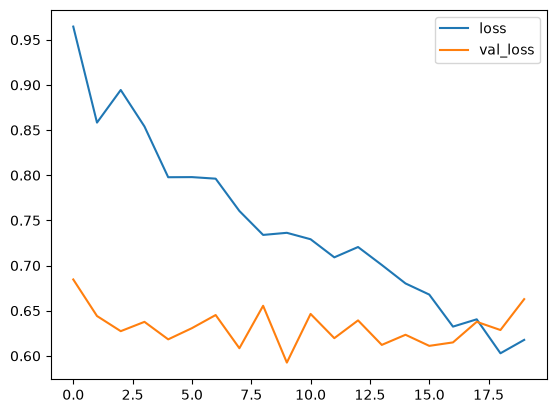

In [202]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

In [203]:
# compare the final model loss/accuracy/evaluation values
# the values should again match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:
[0.5074801445007324, 0.8178777694702148]

Train data evaluation:
[0.4684998095035553, 0.8061147928237915]


In [204]:
# get predictions and convert with argmax() to get categories 
# instead of raw probabilities
test_predictions = model.predict(Xte)
test_predictions = np.argmax(test_predictions, axis=1)



2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


<Axes: >

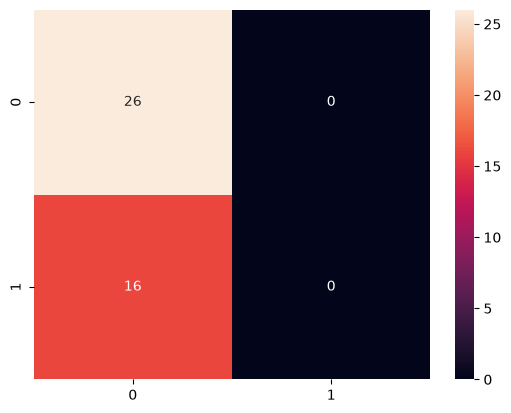

In [205]:


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')



In [207]:

# print the classification report based on true values and predictions
print(classification_report(yte, test_predictions))

# get overall accuracy of the model and print it
acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))



              precision    recall  f1-score   support

           0       0.62      1.00      0.76        26
           1       0.00      0.00      0.00        16

    accuracy                           0.62        42
   macro avg       0.31      0.50      0.38        42
weighted avg       0.38      0.62      0.47        42


Model overall accuracy: 61.90%


c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\FallProject2026\SemesterProjectFall2026\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\FallProject2026\SemesterProjectFall2026\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\FallProject2026\SemesterProjectFall2026\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined 

In [215]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(Xte).ravel() >= 0.7).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
[[26  0]
 [ 8  8]]
              precision    recall  f1-score   support

           0       0.76      1.00      0.87        26
           1       1.00      0.50      0.67        16

    accuracy                           0.81        42
   macro avg       0.88      0.75      0.77        42
weighted avg       0.85      0.81      0.79        42



In [217]:
from sklearn.metrics import classification_report

y_prob = model.predict(Xte).ravel()

print(y_prob[:20])
for threshold in [0.4, 0.5, 0.6, 0.7, 0.8]:
    y_pred = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print(classification_report(yte, y_pred))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
[0.23103414 0.36860496 0.33622018 0.3171162  0.3098445  0.33134055
 0.32837778 0.5110663  0.5401482  0.30412483 0.33296534 0.36347985
 0.55381477 0.5797863  0.6008274  0.6000713  0.40504053 0.3826856
 0.5018491  0.6544571 ]

Threshold: 0.4
              precision    recall  f1-score   support

           0       1.00      0.50      0.67        26
           1       0.55      1.00      0.71        16

    accuracy                           0.69        42
   macro avg       0.78      0.75      0.69        42
weighted avg       0.83      0.69      0.68        42


Threshold: 0.5
              precision    recall  f1-score   support

           0       1.00      0.54      0.70        26
           1       0.57      1.00      0.73        16

    accuracy                           0.71        42
   macro avg       0.79      0.77      0.71        42
weighted avg       0.84      0.71      0.71        42


Threshold: 0.6
              precision    recall  f

In [ ]:
# runs = ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]

# test_run = "A1"
# val_run = "A2"
# train_runs = [r for r in runs if r not in (test_run, val_run)]

# print(train_runs)

['A3', 'B1', 'B2', 'B3', 'B4']


In [ ]:
# def build_model(input_shape):
#     model = keras.Sequential([
#         layers.Input(shape=input_shape),
#         layers.Conv1D(8, 7, padding="same", activation="relu"),
#         layers.MaxPooling1D(2),
#         layers.Conv1D(16, 5, padding="same", activation="relu"),
#         layers.GlobalMaxPooling1D(),
#         layers.Dropout(0.3),
#         layers.Dense(16, activation="relu"),
#         layers.Dense(1, activation="sigmoid"),
#     ])
#     model.compile(optimizer="adam", loss="binary_crossentropy")
#     return model

In [ ]:
# scores = {}

# for i, test_run in enumerate(runs):
#     val_run = runs[(i + 1) % len(runs)]
#     train_runs = [r for r in runs if r not in (test_run, val_run)]

#     Xtr, ytr = get_clips(train_runs)
#     Xva, yva = get_clips([val_run])
#     Xte, yte = get_clips([test_run])

#     n_features = Xtr.shape[-1]
#     scaler = StandardScaler().fit(Xtr.reshape(-1, n_features))
#     Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
#     Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
#     Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

#     keras.backend.clear_session()
#     model = build_model(Xtr.shape[1:])

#     model.fit(
#         Xtr, ytr,
#         validation_data=(Xva, yva),
#         epochs=30,
#         batch_size=32,
#         class_weight={0: 1.0, 1: 3.0},
#         verbose=0,
#         callbacks=[keras.callbacks.EarlyStopping(
#             monitor="val_loss", patience=5, restore_best_weights=True)],
#     )

#     probs = model.predict(Xte, verbose=0).ravel()
#     scores[test_run] = average_precision_score(yte, probs)
#     print(test_run, "score:", round(scores[test_run], 2),
#           "| random guess:", round(yte.mean(), 2))

# print("mean:", sum(scores.values()) / len(scores))

A1 score: 0.68 | random guess: 0.28
A2 score: 0.66 | random guess: 0.25
A3 score: 0.53 | random guess: 0.22
B1 score: 0.73 | random guess: 0.45
B2 score: 0.78 | random guess: 0.3
B3 score: 0.71 | random guess: 0.37
B4 score: 0.51 | random guess: 0.39
mean: 0.6573232453752184
